# Regressão Multivariada: Exposição à Docência Fora da Área e Física

## 1. Configuração e Amostra Analítica

In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Caminhos do projeto
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
INDICADORES = ROOT / "data" / "processed" / "indicadores"
ENEM = ROOT / "data" / "processed" / "enem"
FIGURAS = ROOT / "results" / "figuras"
TABELAS = ROOT / "results" / "tabelas"
FIGURAS.mkdir(parents=True, exist_ok=True)
TABELAS.mkdir(parents=True, exist_ok=True)

# Padrão visual dos gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})
ORDEM_REDE = ["Federal", "Privada", "Municipal", "Estadual"]
CORES_REDE = {"Federal": "#1b9e77", "Privada": "#7570b3", "Municipal": "#e6ab02", "Estadual": "#d95f02"}
FONTE = "Fonte: elaboração própria a partir de INEP (ENEM 2024, Censo Escolar 2024 e INSE 2023)."
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_rows(40)


def salvar(fig, nome):
    # Adiciona a fonte no rodapé e exporta em 300 DPI
    fig.text(0.01, -0.03, FONTE, fontsize=8, color="gray", ha="left")
    fig.savefig(FIGURAS / nome)
    plt.show()


# Base analítica: escolas pareadas Censo x ENEM com ao menos 10 presentes
base = (
    pl.read_parquet(INDICADORES / "indicadores_ensino_medio_2024.parquet")
    .join(pl.read_parquet(ENEM / "enem_escolas_2024.parquet"), left_on="CO_ENTIDADE", right_on="CO_ESCOLA", how="inner")
    .filter(pl.col("IN_MIN_10_ALUNOS"))
)
print(f"Escolas analisadas: {base.height:,}")

Escolas analisadas: 22,999


In [2]:
def ajustar(formula, dados, cluster="CO_MUNICIPIO"):
    # MQO com erros-padrão agrupados (cluster) e controle de nulos
    df = dados.to_pandas()
    grupos = df[cluster].astype("category").cat.codes.to_numpy()
    return smf.ols(formula, data=df).fit(cov_type="cluster", cov_kwds={"groups": grupos})


def estrelas(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""


def extrair(modelo, nome):
    # Coeficientes (sem dummies de UF), N e R² ajustado em formato longo
    ci = modelo.conf_int()
    linhas = [
        {"MODELO": nome, "TERMO": t, "COEF": modelo.params[t], "EP_CLUSTER": modelo.bse[t],
         "IC95_INF": ci.loc[t, 0], "IC95_SUP": ci.loc[t, 1], "P_VALOR": modelo.pvalues[t]}
        for t in modelo.params.index if not t.startswith("C(SG_UF")
    ]
    linhas.append({"MODELO": nome, "TERMO": "N", "COEF": float(modelo.nobs)})
    linhas.append({"MODELO": nome, "TERMO": "R2_AJUSTADO", "COEF": modelo.rsquared_adj})
    return pl.DataFrame(linhas, schema={"MODELO": pl.String, "TERMO": pl.String, "COEF": pl.Float64,
                                        "EP_CLUSTER": pl.Float64, "IC95_INF": pl.Float64,
                                        "IC95_SUP": pl.Float64, "P_VALOR": pl.Float64})


def quadro(tabela):
    # Quadro compacto: coeficiente (erro-padrão) com estrelas de significância
    return (
        tabela.with_columns(
            pl.when(pl.col("EP_CLUSTER").is_null())
            .then(pl.col("COEF").round(3).cast(pl.String))
            .otherwise(
                pl.format("{} ({}){}", pl.col("COEF").round(3), pl.col("EP_CLUSTER").round(3),
                          pl.col("P_VALOR").map_elements(estrelas, return_dtype=pl.String))
            ).alias("VALOR")
        )
        .pivot(on="MODELO", index="TERMO", values="VALOR", aggregate_function="first")
    )


# Amostra completa nos regressores; AFD reescalado para +10 p.p. de docentes
REGRESSORES = ["AFD_MED_CAT_1", "AFD_MED_CAT_3", "TDI_MED_TOTAL", "ATU_MED_TOTAL", "DSU_MED_DOC_SUPERIOR",
               "TX_ABSTENCAO_DIA2", "NO_CATEGORIA", "NO_DEPENDENCIA", "SG_UF", "CO_MUNICIPIO"]
dados = base.drop_nulls(REGRESSORES).with_columns(
    (pl.col("AFD_MED_CAT_3") / 10).alias("AFD_G3_10"),
    (pl.col("AFD_MED_CAT_1") / 10).alias("AFD_G1_10"),
)
REDE = 'C(NO_DEPENDENCIA, Treatment(reference="Estadual"))'
CONTROLES = "TDI_MED_TOTAL + ATU_MED_TOTAL + DSU_MED_DOC_SUPERIOR + TX_ABSTENCAO_DIA2 + C(NO_CATEGORIA) + C(SG_UF)"
print(f"Amostra analítica: {dados.height:,} escolas | {dados['CO_MUNICIPIO'].n_unique():,} municípios (clusters)")

Amostra analítica: 22,776 escolas | 5,171 municípios (clusters)


## 2. Especificações Progressivas MQO (AFD Grupo 3)

In [3]:
# M1 bivariado -> M2 + rede -> M3 + controles e efeito fixo de UF (erros agrupados por município)
m1 = ajustar("PCT_ACERTO_FISICA ~ AFD_G3_10", dados)
m2 = ajustar(f"PCT_ACERTO_FISICA ~ AFD_G3_10 + {REDE}", dados)
m3 = ajustar(f"PCT_ACERTO_FISICA ~ AFD_G3_10 + {REDE} + {CONTROLES}", dados)
for nome, m in [("M1", m1), ("M2", m2), ("M3", m3)]:
    print(f"{nome}: AFD G3 (+10 p.p.) = {m.params['AFD_G3_10']:+.3f} p.p. | IC95 = [{m.conf_int().loc['AFD_G3_10', 0]:+.3f}; "
          f"{m.conf_int().loc['AFD_G3_10', 1]:+.3f}] | p = {m.pvalues['AFD_G3_10']:.2e} | R² aj. = {m.rsquared_adj:.3f}")

M1: AFD G3 (+10 p.p.) = -1.137 p.p. | IC95 = [-1.284; -0.990] | p = 7.06e-52 | R² aj. = 0.048
M2: AFD G3 (+10 p.p.) = -0.537 p.p. | IC95 = [-0.625; -0.450] | p = 1.30e-33 | R² aj. = 0.557
M3: AFD G3 (+10 p.p.) = -0.444 p.p. | IC95 = [-0.530; -0.357] | p = 7.08e-24 | R² aj. = 0.668


## 3. Modelo Espelho (AFD Grupo 1) e Diagnóstico VIF

In [4]:
# Mesmo M3 trocando G3 por G1 (sinal esperado oposto)
m3_g1 = ajustar(f"PCT_ACERTO_FISICA ~ AFD_G1_10 + {REDE} + {CONTROLES}", dados)

tab03 = pl.concat([extrair(m1, "M1_G3"), extrair(m2, "M2_G3"), extrair(m3, "M3_G3"), extrair(m3_g1, "M3_G1")])
tab03.write_csv(TABELAS / "tab03_regressao_ols_redes.csv")
quadro(tab03)

TERMO,M1_G3,M2_G3,M3_G3,M3_G1
str,str,str,str,str
"""Intercept""","""31.167 (0.302)***""","""26.054 (0.163)***""","""14.979 (0.781)***""","""14.425 (0.79)***"""
"""AFD_G3_10""","""-1.137 (0.075)***""","""-0.537 (0.044)***""","""-0.444 (0.044)***""",null
"""N""","""22776.0""","""22776.0""","""22776.0""","""22776.0"""
"""R2_AJUSTADO""","""0.048""","""0.557""","""0.668""","""0.667"""
"""C(NO_DEPENDENCIA, Treatment(re…",null,"""9.569 (0.302)***""","""8.125 (0.273)***""","""8.509 (0.273)***"""
"""C(NO_DEPENDENCIA, Treatment(re…",null,"""3.899 (0.876)***""","""2.354 (0.675)***""","""2.36 (0.665)***"""
"""C(NO_DEPENDENCIA, Treatment(re…",null,"""12.249 (0.151)***""","""9.813 (0.183)***""","""9.883 (0.177)***"""
"""C(NO_CATEGORIA)[T.Urbana]""",null,null,"""0.731 (0.139)***""","""0.742 (0.137)***"""
"""TDI_MED_TOTAL""",null,null,"""-0.08 (0.007)***""","""-0.08 (0.007)***"""


In [5]:
# VIF dos preditores contínuos do M3 (critério de aceitação: VIF < 5)
CONT = ["AFD_G3_10", "TDI_MED_TOTAL", "ATU_MED_TOTAL", "DSU_MED_DOC_SUPERIOR", "TX_ABSTENCAO_DIA2"]
X = np.column_stack([np.ones(dados.height), dados.select(CONT).to_numpy()])
pl.DataFrame({"VARIAVEL": CONT, "VIF": [round(variance_inflation_factor(X, i + 1), 2) for i in range(len(CONT))]})

VARIAVEL,VIF
str,f64
"""AFD_G3_10""",1.08
"""TDI_MED_TOTAL""",1.21
"""ATU_MED_TOTAL""",1.02
"""DSU_MED_DOC_SUPERIOR""",1.01
"""TX_ABSTENCAO_DIA2""",1.28


## 4. Gráfico de Coeficientes (Forest Plot)

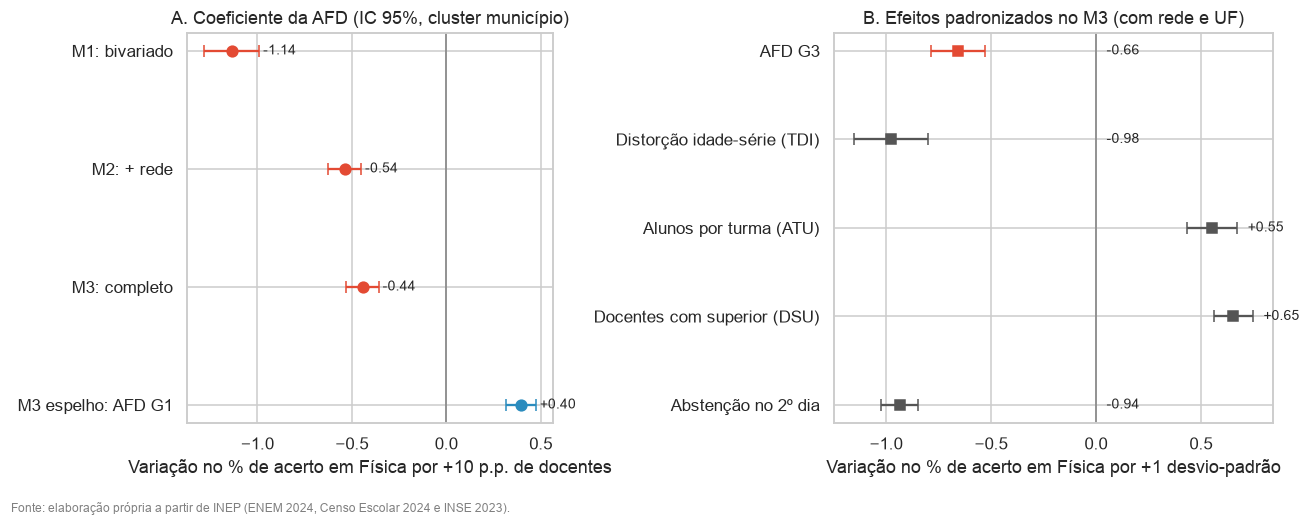

In [6]:
# Painel A: trajetória do coeficiente de AFD entre modelos | Painel B: efeito de +1 desvio-padrão no M3
def ic(m, t):
    c = m.conf_int().loc[t]
    return m.params[t], c[0], c[1]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.2]})

traj = [("M1: bivariado", ic(m1, "AFD_G3_10"), "#e34a33"), ("M2: + rede", ic(m2, "AFD_G3_10"), "#e34a33"),
        ("M3: completo", ic(m3, "AFD_G3_10"), "#e34a33"), ("M3 espelho: AFD G1", ic(m3_g1, "AFD_G1_10"), "#2b8cbe")]
for y, (rot, (c, lo, hi), cor) in enumerate(traj):
    axa.errorbar(c, y, xerr=[[c - lo], [hi - c]], fmt="o", color=cor, capsize=4, ms=7)
    axa.text(hi + 0.02, y, f"{c:+.2f}", va="center", fontsize=9)
axa.axvline(0, color="gray", lw=1)
axa.set_yticks(range(len(traj)), [t[0] for t in traj])
axa.invert_yaxis()
axa.set_xlabel("Variação no % de acerto em Física por +10 p.p. de docentes")
axa.set_title("A. Coeficiente da AFD (IC 95%, cluster município)")

nomes = {"AFD_G3_10": "AFD G3", "TDI_MED_TOTAL": "Distorção idade-série (TDI)", "ATU_MED_TOTAL": "Alunos por turma (ATU)",
         "DSU_MED_DOC_SUPERIOR": "Docentes com superior (DSU)", "TX_ABSTENCAO_DIA2": "Abstenção no 2º dia"}
for y, (t, rot) in enumerate(nomes.items()):
    dp = dados[t].std()
    c, lo, hi = (v * dp for v in ic(m3, t))
    axb.errorbar(c, y, xerr=[[c - lo], [hi - c]], fmt="s", color="#e34a33" if t == "AFD_G3_10" else "#555555", capsize=4, ms=6)
    axb.text(max(hi, 0) + 0.05, y, f"{c:+.2f}", va="center", fontsize=9)
axb.axvline(0, color="gray", lw=1)
axb.set_yticks(range(len(nomes)), list(nomes.values()))
axb.invert_yaxis()
axb.set_xlabel("Variação no % de acerto em Física por +1 desvio-padrão")
axb.set_title("B. Efeitos padronizados no M3 (com rede e UF)")
fig.tight_layout()
salvar(fig, "fig04_forest_plot_ols_redes.png")